# Exploratory analysis of the station-hour panel

The modeling table is one row per Indego station-hour from January 2024 through the last
published trip (June 30, 2026). This notebook does not fit a demand model. It checks what
the joined table actually contains, and it looks at the patterns the project plan calls out:
clock time and recent ridership, weather, sports, bike availability, the Q3 2025 SEPTA
service cut and fare increase, and the June 2026 World Cup matches in Philadelphia.

Definitions used below:

- **Departures** are completed trips starting at that station in that hour. A zero can mean
  low demand or an empty dock. Indego does not publish the trips that could not start.
- **Per station** divides a total by the number of stations in service that hour or day, so
  network growth is not mistaken for heavier use.
- **Nearby sports** means the nearest final ESPN game that hour is within 1.5 km. The venues
  are the South Philadelphia sports complex (Phillies, Eagles, 76ers/Flyers).
- **SEPTA service cut:** August 24 through September 13, 2025. **Fare increase:** September 14,
  2025 onward. Source: City of Philadelphia notice on the August 2025 cuts.
- **World Cup match days in the trip file:** June 14, 19, 22, 25, and 27, 2026, at Lincoln
  Financial Field. The July 4, 2026 round-of-16 match is also the semiquincentennial, and it
  is outside the published quarterly trip files.

Figures are written to figures/.


## Colab

The Colab kernel runs on a Google server. It cannot read the project folder on your computer.
This notebook reads data/processed/ written by 01_data_joining.ipynb. Run that notebook first, in this same runtime. A restarted runtime is empty and cannot see files on your computer.

Connect the kernel with **Select Kernel → Colab → Auto Connect**, then run the cells from the top.


In [4]:
import sys
import json
import hashlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")

    import subprocess
    for package, module in [
        ('numpy', 'numpy'),
        ('pandas', 'pandas'),
        ('pyarrow', 'pyarrow'),
        ('matplotlib', 'matplotlib'),
        ('seaborn', 'seaborn')
    ]:
        if importlib.util.find_spec(module) is None:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

if IN_COLAB:
    ROOT = Path("/content/drive/MyDrive/Milestone II")
else:
    ROOT = Path.cwd().resolve()

PROCESSED = ROOT / "data/processed"
SHARED = ROOT / "data/shared"

settings_path = ROOT / "project_settings.json"
if not settings_path.is_file():
    raise FileNotFoundError(f"Missing {settings_path}. Check your project folder.")

settings = json.loads(settings_path.read_text())

import numpy as np
import pandas as pd

STUDY_START = pd.Timestamp(settings["study_start"])
TRAIN_END = pd.Timestamp(settings["train_end"])
VAL_END = pd.Timestamp(settings["validation_end"])
TEST_END = pd.Timestamp(settings["test_end"])
PROFILE_AVAILABLE_FROM = pd.Timestamp(settings["forecast_profiles_available_from"])
CV_WINDOWS = settings["forward_validation_windows"]

assert STUDY_START < PROFILE_AVAILABLE_FROM < TRAIN_END < VAL_END < TEST_END
assert all(PROFILE_AVAILABLE_FROM < pd.Timestamp(a) < pd.Timestamp(b) <= VAL_END
           for a, b in CV_WINDOWS)

if settings["timezone"] != "America/New_York":
    raise ValueError("The prepared timestamps use Philadelphia local time. Rebuild data before changing timezone.")

missing = [name for name in ["trips_clean.parquet", "station_hour.parquet", "stations.parquet"]
           if not (PROCESSED / name).is_file()]

if missing:
    raise FileNotFoundError(f"Missing processed files: {missing}. Run 01 or copy the agreed processed data here.")

print("Project:", ROOT)
print(f"Training: {STUDY_START.date()} to {(TRAIN_END - pd.Timedelta(days=1)).date()}")
print(f"Validation: {TRAIN_END.date()} to {(VAL_END - pd.Timedelta(days=1)).date()}")
print(f"Test: {VAL_END.date()} to {(TEST_END - pd.Timedelta(days=1)).date()}")

Project: /content/drive/MyDrive/Milestone II
Training: 2024-01-01 to 2025-12-31
Validation: 2026-01-01 to 2026-03-31
Test: 2026-04-01 to 2026-06-30


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

def haversine_km(lat1, lon1, lat2, lon2):
    """Calculate straight-line distance between latitude/longitude pairs in kilometres."""
    lat1 = np.radians(np.asarray(lat1, dtype="float64"))
    lon1 = np.radians(np.asarray(lon1, dtype="float64"))
    lat2 = np.radians(np.asarray(lat2, dtype="float64"))
    lon2 = np.radians(np.asarray(lon2, dtype="float64"))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 6371.0088 * 2.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def save_figure(path, dpi=160, tight=True):
    """Save the figure, show it here and release it from memory."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if tight:
        plt.tight_layout()
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Saved", path.name)

In [6]:

print("Project:", ROOT)

FIGURES = ROOT / "figures/eda"
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

LFF = (39.900833, -75.167500)
DOW_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# The common path check already covered the three Parquet files.
required = [
    PROCESSED / "cleaning_report.csv",
    PROCESSED / "coverage_by_month.csv",
]
missing = [path for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Processed tables are not on this runtime:\n"
        + "\n".join(f"  {path}" for path in missing)
    )

panel = pd.read_parquet(
    PROCESSED / "station_hour.parquet",
    columns=[
        "station_id",
        "hour",
        "departures",
        "arrivals",
        "net_flow",
        "departures_lag_1",
        "departures_lag_24",
        "departures_lag_168",
        "hour_of_day",
        "day_of_week",
        "is_weekend",
        "temperature_c",
        "precipitation_mm",
        "is_holiday",
        "holiday_name",
        "typical_city_departures",
        "wx_rain",
        "wx_heat",
        "wx_snow",
        "sports_any",
        "sports_league",
        "near_sports",
        "bikes_available",
        "zero_bikes",
        "is_septa_service_cut",
        "is_septa_fare_increase",
        "is_fifa_match_day",
        "is_fifa_match_hour",
    ],
)
panel = panel.loc[panel.hour.ge(STUDY_START) & panel.hour.lt(TEST_END)].copy()
panel["date"] = panel["hour"].dt.normalize()
stations = pd.read_parquet(
    PROCESSED / "stations.parquet",
    columns=["station_id", "station_name", "lat", "lon", "district", "status", "go_live"],
)
cleaning = pd.read_csv(PROCESSED / "cleaning_report.csv")
coverage = pd.read_csv(PROCESSED / "coverage_by_month.csv")
print(f"Station-hours: {len(panel):,}")
print(f"Window: {panel['hour'].min()} to {panel['hour'].max()}")
print(f"Stations appearing in the panel: {panel['station_id'].nunique():,}")

Project: /content/drive/MyDrive/Milestone II
Station-hours: 5,950,039
Window: 2024-01-01 00:00:00 to 2026-06-30 23:00:00
Stations appearing in the panel: 339


## What survived cleaning, and what the join actually covers

Indego's own publish step already removes staff trips, sub-minute trips, and durations over
24 hours, so almost every raw row is usable. The remaining losses are the virtual staff
station and a handful of coordinates outside Philadelphia. About 1.5% of kept trips have no
real end station; they still count as departures.

Weather from DisPatch70 situations joins to every station-hour. Station status does not.
Status files are missing for much of early 2024, and even in published months many
station-hours have no snapshot. Those hours stay missing. They are not coded as zero bikes.



Trips with no real end station: 51,217 (1.5% of kept trips)


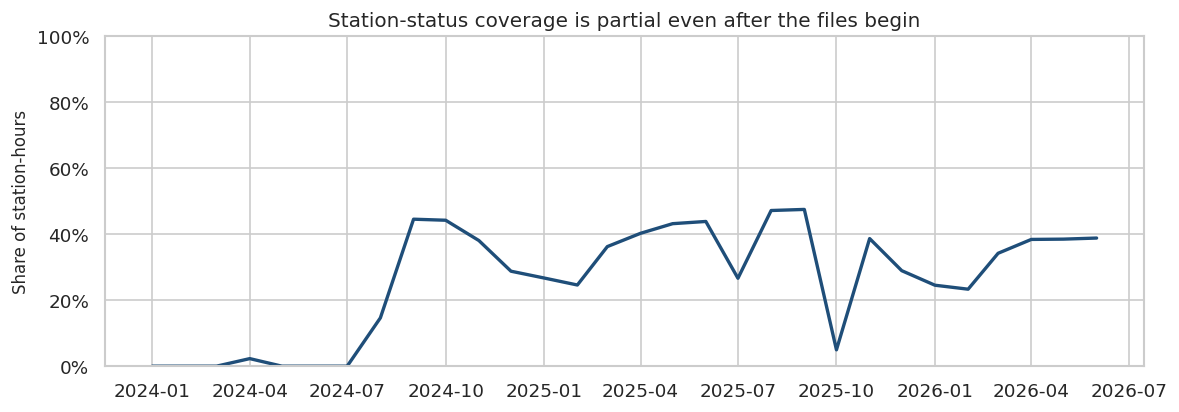

Saved 01_status_coverage.png


In [8]:
kept = int(cleaning.loc[cleaning["step"].eq("rows_kept"), "rows"].iloc[0])
no_end = int(cleaning.loc[cleaning["step"].eq("departures_with_no_real_end_station"), "rows"].iloc[0])
print(f"\nTrips with no real end station: {no_end:,} ({no_end / kept:.1%} of kept trips)")

monthly = coverage.copy()
monthly["year_month"] = pd.PeriodIndex(monthly["year_month"], freq="M").to_timestamp()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(monthly["year_month"], monthly["status_coverage"], color="#1f4e79", lw=2)
ax.set_ylim(0, 1)
ax.set_ylabel("Share of station-hours")
ax.set_xlabel("")
ax.set_title("Station-status coverage is partial even after the files begin")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:.0%}"))
save_figure(FIGURES / "01_status_coverage.png", dpi=140)

## Calendar pattern

Demand is seasonal and strongly tied to the clock. The same-hour lag, the same hour yesterday,
and the same hour last week all move with departures. That is the baseline the project wants
to beat before weather and events are given credit.

The heatmap is the mean departure count per in-service station, so a larger network does not
inflate later years inside a single cell.


Correlation of departures with recent ridership at the same station:
                    departures
departures_lag_1         0.462
departures_lag_24        0.472
departures_lag_168       0.489


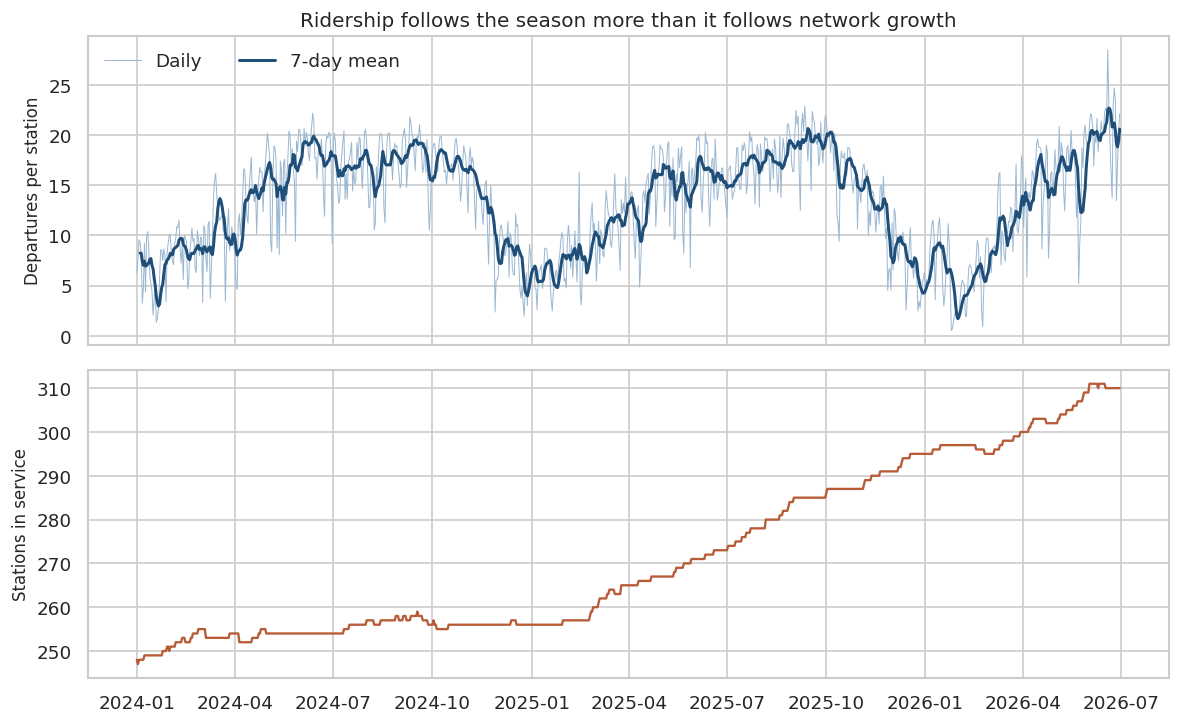

Saved 02_daily_demand.png


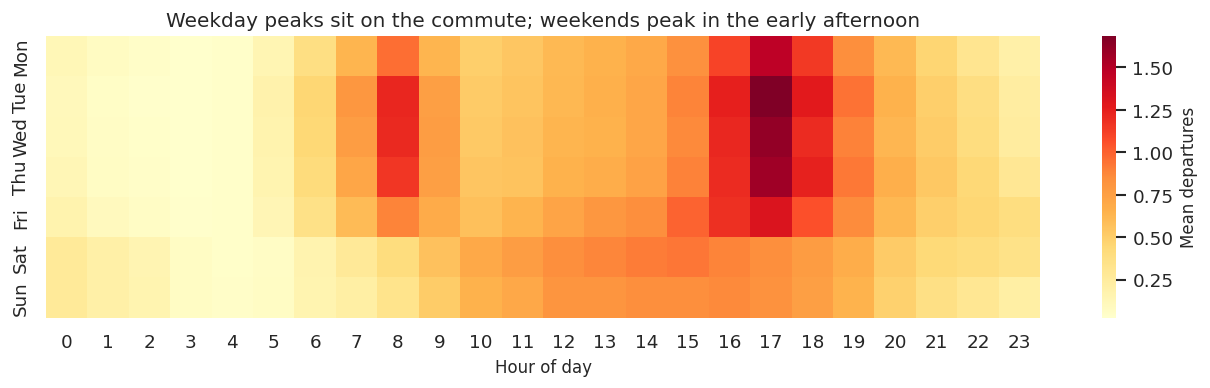

Saved 03_hour_weekday.png
DisPatch70's typical profile matches the average daily cycle (correlation of the 24 hour-of-day shares: 1.000). Hour by hour, city departures correlate with that profile at 0.792, so it is not a copy of the observed count.


In [9]:
lag_corr = panel[["departures", "departures_lag_1", "departures_lag_24", "departures_lag_168"]].corr()
print("Correlation of departures with recent ridership at the same station:")
print(lag_corr.loc[["departures_lag_1", "departures_lag_24", "departures_lag_168"], ["departures"]].round(3))

daily = panel.groupby("date", as_index=False).agg(
    departures=("departures", "sum"),
    stations=("station_id", "nunique"),
)
daily["per_station"] = daily["departures"] / daily["stations"]
daily["roll7"] = daily["per_station"].rolling(7, min_periods=4).mean()

fig, axes = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True)
axes[0].plot(daily["date"], daily["per_station"], color="#9bb8d3", lw=0.6, label="Daily")
axes[0].plot(daily["date"], daily["roll7"], color="#1f4e79", lw=1.8, label="7-day mean")
axes[0].set_ylabel("Departures per station")
axes[0].set_title("Ridership follows the season more than it follows network growth")
axes[0].legend(frameon=False, ncol=2)
axes[1].plot(daily["date"], daily["stations"], color="#b85c38", lw=1.4)
axes[1].set_ylabel("Stations in service")
axes[1].set_xlabel("")
save_figure(FIGURES / "02_daily_demand.png", dpi=140)


heat = (
    panel.groupby(["day_of_week", "hour_of_day"])["departures"]
    .mean()
    .unstack("hour_of_day")
    .reindex(range(7))
)
fig, ax = plt.subplots(figsize=(11, 3.4))
sns.heatmap(
    heat,
    ax=ax,
    cmap="YlOrRd",
    yticklabels=DOW_NAMES,
    cbar_kws={"label": "Mean departures"},
)
ax.set_xlabel("Hour of day")
ax.set_ylabel("")
ax.set_title("Weekday peaks sit on the commute; weekends peak in the early afternoon")
save_figure(FIGURES / "03_hour_weekday.png", dpi=140)


shape = panel.groupby("hour_of_day").agg(
    observed=("departures", "sum"),
    typical=("typical_city_departures", "sum"),
)
shape = shape / shape.sum()
by_hour = panel.groupby("hour", as_index=False).agg(
    departures=("departures", "sum"),
    typical=("typical_city_departures", "first"),
)
print(
    "DisPatch70's typical profile matches the average daily cycle "
    f"(correlation of the 24 hour-of-day shares: {shape['observed'].corr(shape['typical']):.3f}). "
    "Hour by hour, city departures correlate with that profile at "
    f"{by_hour['departures'].corr(by_hour['typical']):.3f}, so it is not a copy of the observed count."
)

## Trip mix

Most rides are short. The median duration is about 10 minutes and the median distance is
about 1.5 km, which is a neighborhood trip rather than a cross-city trip. Electric bikes
are the majority of trips by 2024 and a larger share in later summers. Passes are dominated
by monthly and annual memberships; walk-up and day passes are the flexible remainder.


Median duration: 10 min; 99th percentile: 83 min
Median one-way distance: 1.56 km
Round-trip share: 6.2%


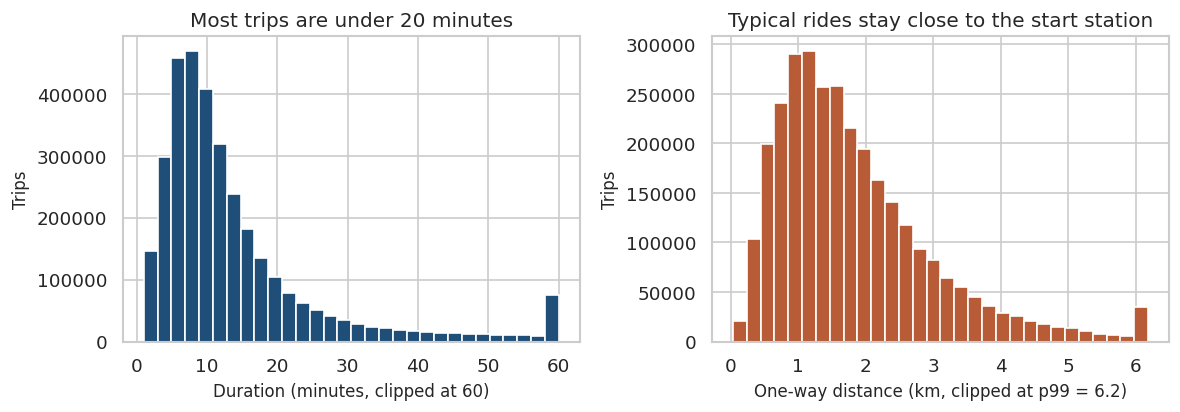

Saved 04_duration_distance.png


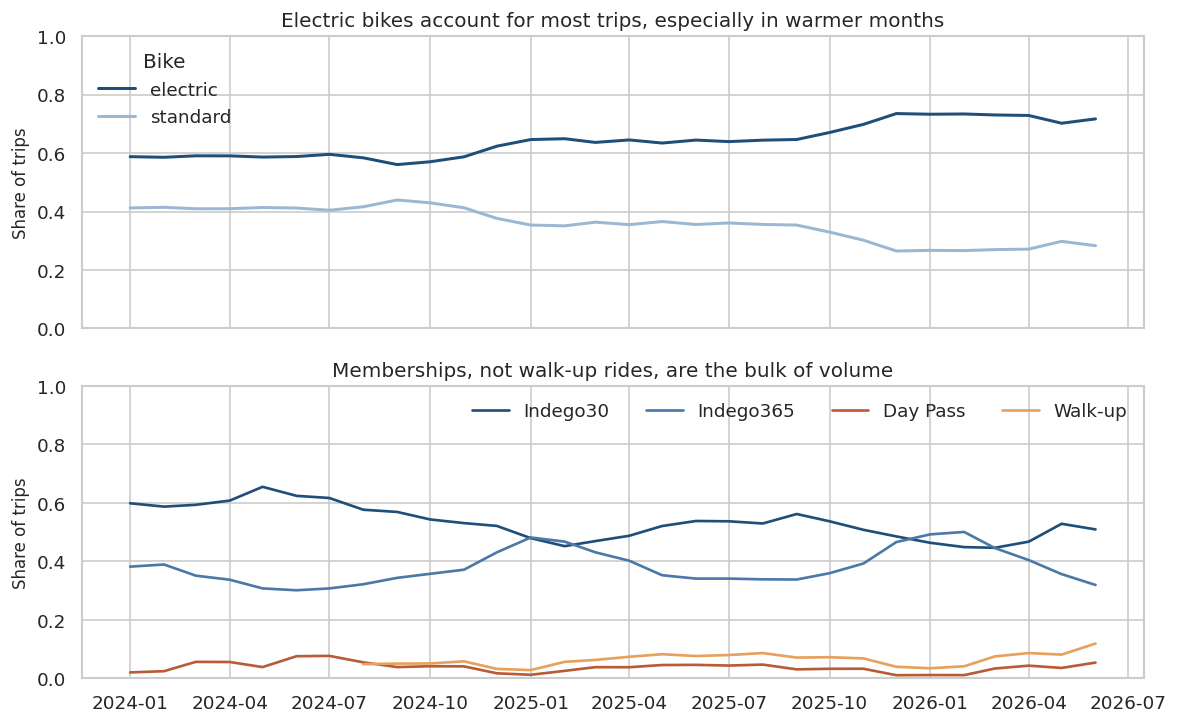

Saved 05_bike_and_pass_mix.png


In [10]:
trips = pd.read_parquet(
    PROCESSED / "trips_clean.parquet",
    columns=["start_time", "duration_min", "distance_km", "bike_type", "passholder_type", "trip_route_category"],
)
print(f"Median duration: {trips['duration_min'].median():.0f} min; 99th percentile: {trips['duration_min'].quantile(0.99):.0f} min")
trips = trips.loc[trips.start_time.ge(STUDY_START) & trips.start_time.lt(TEST_END)].copy()

one_way = trips["trip_route_category"].astype("string").str.lower().eq("one way")
print(f"Median one-way distance: {trips.loc[one_way, 'distance_km'].median():.2f} km")
print(f"Round-trip share: {(~one_way).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
duration = trips["duration_min"].clip(upper=60)
axes[0].hist(duration, bins=30, color="#1f4e79", edgecolor="white")
axes[0].set_xlabel("Duration (minutes, clipped at 60)")
axes[0].set_ylabel("Trips")
axes[0].set_title("Most trips are under 20 minutes")
distance = trips.loc[one_way, "distance_km"].dropna()
cap = float(distance.quantile(0.99))
axes[1].hist(distance.clip(upper=cap), bins=30, color="#b85c38", edgecolor="white")
axes[1].set_xlabel(f"One-way distance (km, clipped at p99 = {cap:.1f})")
axes[1].set_ylabel("Trips")
axes[1].set_title("Typical rides stay close to the start station")
save_figure(FIGURES / "04_duration_distance.png", dpi=140)


trips["month"] = trips["start_time"].dt.to_period("M").dt.to_timestamp()
mix = trips.groupby(["month", "bike_type"]).size().rename("trips").reset_index()
mix["share"] = mix["trips"] / mix.groupby("month")["trips"].transform("sum")
passes = trips.copy()
passes["passholder_type"] = passes["passholder_type"].where(
    passes["passholder_type"].isin(["Indego30", "Indego365", "Walk-up", "Day Pass"]),
    "Other",
)
pass_mix = passes.groupby(["month", "passholder_type"]).size().rename("trips").reset_index()
pass_mix["share"] = pass_mix["trips"] / pass_mix.groupby("month")["trips"].transform("sum")

fig, axes = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True)
for bike_type, color in [("electric", "#1f4e79"), ("standard", "#9bb8d3")]:
    part = mix.loc[mix["bike_type"].eq(bike_type)]
    axes[0].plot(part["month"], part["share"], label=bike_type, color=color, lw=1.8)
axes[0].set_ylabel("Share of trips")
axes[0].set_ylim(0, 1)
axes[0].legend(frameon=False, title="Bike")
axes[0].set_title("Electric bikes account for most trips, especially in warmer months")
for pass_type, color in [
    ("Indego30", "#1f4e79"),
    ("Indego365", "#4c78a8"),
    ("Day Pass", "#b85c38"),
    ("Walk-up", "#e6a15c"),
]:
    part = pass_mix.loc[pass_mix["passholder_type"].eq(pass_type)]
    axes[1].plot(part["month"], part["share"], label=pass_type, color=color, lw=1.6)
axes[1].set_ylabel("Share of trips")
axes[1].set_ylim(0, 1)
axes[1].legend(frameon=False, ncol=4, loc="upper right")
axes[1].set_title("Memberships, not walk-up rides, are the bulk of volume")
save_figure(FIGURES / "05_bike_and_pass_mix.png", dpi=140)

del trips, mix, passes, pass_mix

## Stations do not behave like one another

Total volume is concentrated, and the weekday morning flow splits stations into places
bikes leave and places bikes arrive. Net flow is arrivals minus
departures during weekday hours 7, 8, and 9. Negative means the station is a morning origin.


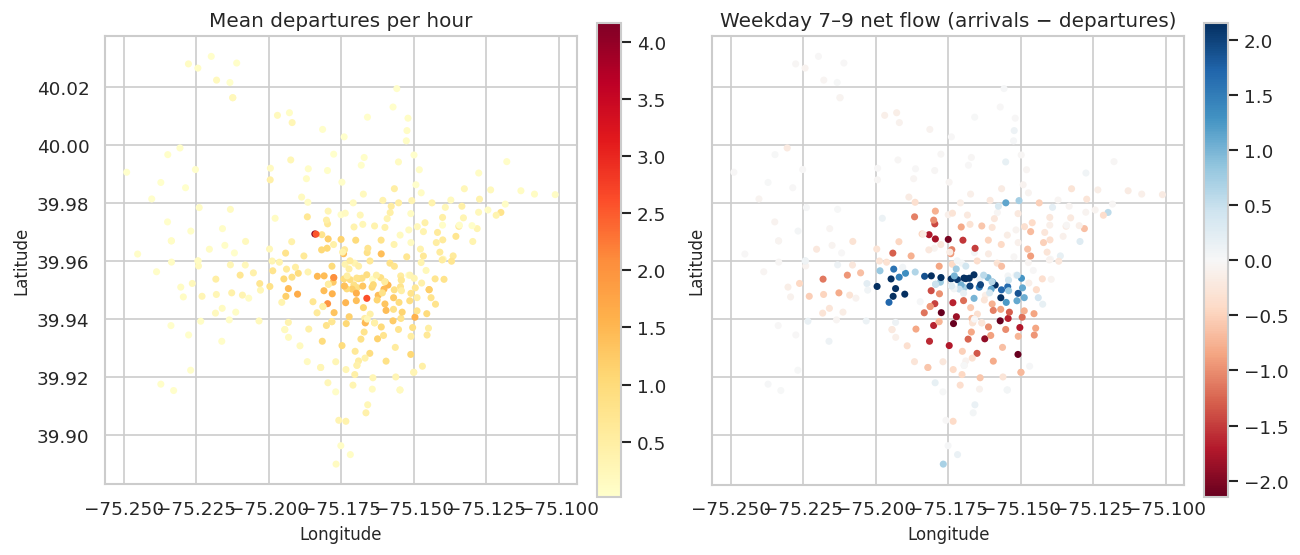

Saved 06_station_maps.png


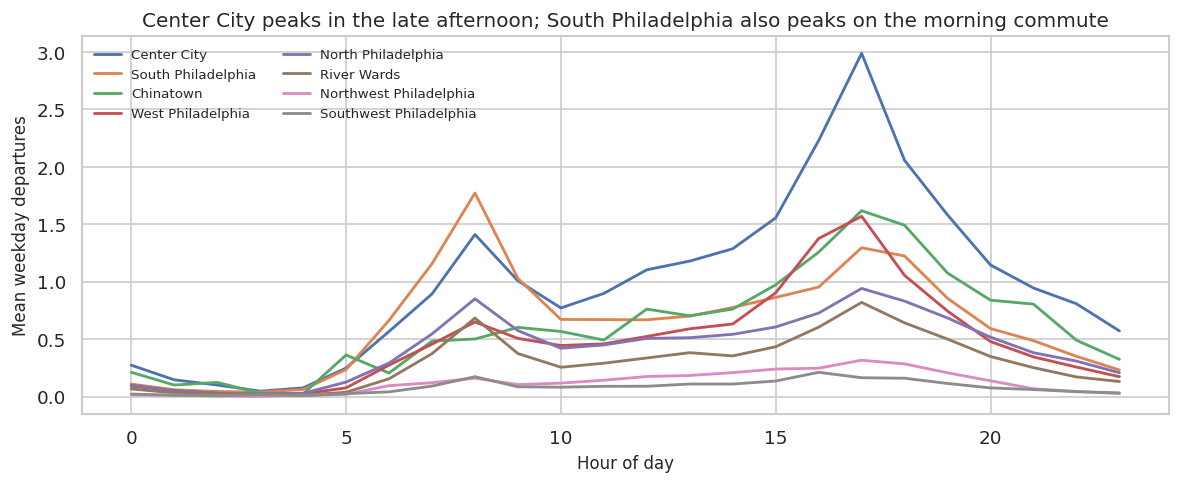

Saved 07_district_profiles.png
Weekday morning net flow, share of stations that are net origins: 66.3%


In [11]:
located = stations.dropna(subset=["lat", "lon"]).copy()
weekday_am = panel.loc[~panel["is_weekend"] & panel["hour_of_day"].between(7, 9)]
morning = weekday_am.groupby("station_id", as_index=False).agg(
    departures=("departures", "mean"),
    net_flow=("net_flow", "mean"),
)
volume = panel.groupby("station_id", as_index=False)["departures"].mean().rename(columns={"departures": "mean_departures"})
located = located.merge(volume, on="station_id", how="inner").merge(morning, on="station_id", how="left")
located["district"] = located["district"].fillna("Unassigned")

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True, sharey=True)
volume_plot = axes[0].scatter(
    located["lon"],
    located["lat"],
    c=located["mean_departures"],
    s=18,
    cmap="YlOrRd",
    linewidths=0,
)
axes[0].set_title("Mean departures per hour")
axes[0].set_aspect("equal")
fig.colorbar(volume_plot, ax=axes[0], fraction=0.046, pad=0.04)
flow_limit = float(np.nanpercentile(np.abs(located["net_flow"]), 95))
flow_plot = axes[1].scatter(
    located["lon"],
    located["lat"],
    c=located["net_flow"].clip(-flow_limit, flow_limit),
    s=18,
    cmap="RdBu",
    linewidths=0,
    vmin=-flow_limit,
    vmax=flow_limit,
)
axes[1].set_title("Weekday 7–9 net flow (arrivals − departures)")
axes[1].set_aspect("equal")
fig.colorbar(flow_plot, ax=axes[1], fraction=0.046, pad=0.04)
for axis in axes:
    axis.set_xlabel("Longitude")
    axis.set_ylabel("Latitude")
save_figure(FIGURES / "06_station_maps.png", dpi=140)


profile = panel.loc[~panel["is_weekend"], ["station_id", "hour_of_day", "departures"]].merge(
    located[["station_id", "district"]], on="station_id", how="inner"
)
district_order = (
    profile.groupby("district")["departures"].mean().sort_values(ascending=False).index.tolist()
)
fig, ax = plt.subplots(figsize=(10, 4.2))
for district in district_order:
    if district == "Unassigned":
        continue
    curve = profile.loc[profile["district"].eq(district)].groupby("hour_of_day")["departures"].mean()
    ax.plot(curve.index, curve.values, label=district, lw=1.7)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean weekday departures")
ax.set_title("Center City peaks in the late afternoon; South Philadelphia also peaks on the morning commute")
ax.legend(frameon=False, ncol=2, fontsize=8)
save_figure(FIGURES / "07_district_profiles.png", dpi=140)

print(
    "Weekday morning net flow, share of stations that are net origins:",
    f"{(located['net_flow'] < 0).mean():.1%}",
)

## Weather

Each clock hour has one city weather reading, repeated across stations. Comparisons below
use departures per in-service station so the result is an hourly rate. Temperature is binned
in 5°C steps. "Wet" means DisPatch70 recorded precipitation in that hour, not an extreme-rain
event flag. The heat and snow flags mark the interval events in the weather-event table.


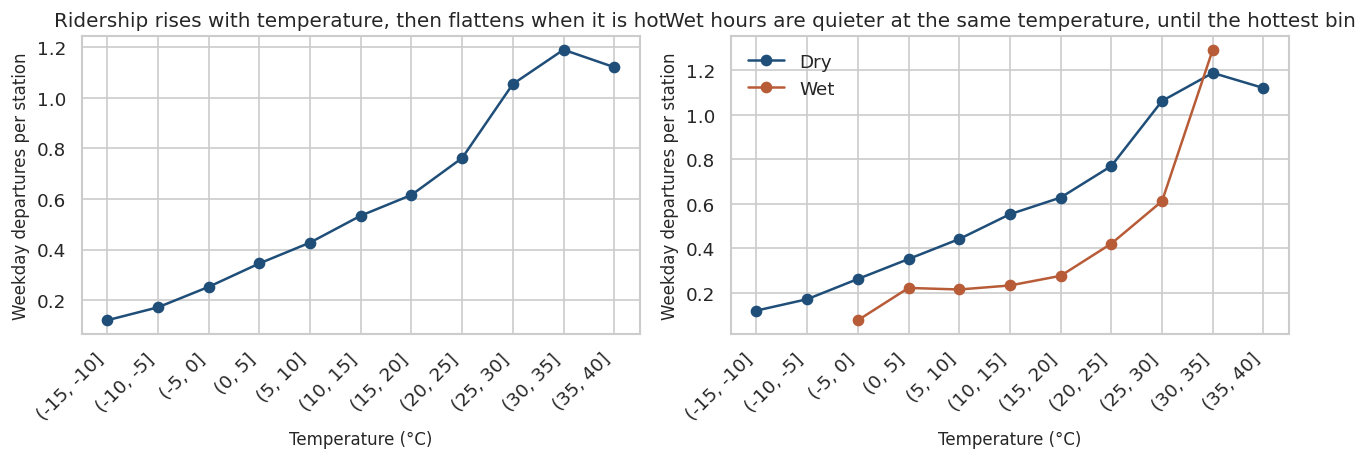

Saved 08_weather.png
Share of clock hours with precipitation: 4.4%
Share of clock hours flagged extreme heat: 5.3%
Share of clock hours flagged snow: 0.7%
Weekday mean departures per station, dry 0.608 vs wet 0.264 (-56.6%)


In [12]:
city = panel.groupby("hour", as_index=False).agg(
    departures=("departures", "sum"),
    stations=("station_id", "nunique"),
    temperature_c=("temperature_c", "first"),
    precipitation_mm=("precipitation_mm", "first"),
    is_weekend=("is_weekend", "first"),
    is_holiday=("is_holiday", "first"),
    holiday_name=("holiday_name", "first"),
    wx_heat=("wx_heat", "first"),
    wx_snow=("wx_snow", "first"),
    hour_of_day=("hour_of_day", "first"),
    day_of_week=("day_of_week", "first"),
)
city["per_station"] = city["departures"] / city["stations"]
city["date"] = city["hour"].dt.normalize()
city["temp_bin"] = pd.cut(city["temperature_c"], bins=np.arange(-15, 41, 5))
city["wet"] = city["precipitation_mm"].gt(0)

weekday = city.loc[~city["is_weekend"] & ~city["is_holiday"].fillna(False)]
temp_curve = weekday.groupby("temp_bin", observed=True)["per_station"].mean()
wet_curve = (
    weekday.groupby(["temp_bin", "wet"], observed=True)["per_station"].mean().unstack("wet")
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(len(temp_curve)), temp_curve.to_numpy(), marker="o", color="#1f4e79")
axes[0].set_xticks(np.arange(len(temp_curve)))
axes[0].set_xticklabels([str(interval) for interval in temp_curve.index], rotation=45, ha="right")
axes[0].set_ylabel("Weekday departures per station")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_title("Ridership rises with temperature, then flattens when it is hot")
if wet_curve.shape[1] == 2:
    axes[1].plot(np.arange(len(wet_curve)), wet_curve[False], marker="o", label="Dry", color="#1f4e79")
    axes[1].plot(np.arange(len(wet_curve)), wet_curve[True], marker="o", label="Wet", color="#b85c38")
    axes[1].set_xticks(np.arange(len(wet_curve)))
    axes[1].set_xticklabels([str(interval) for interval in wet_curve.index], rotation=45, ha="right")
axes[1].legend(frameon=False)
axes[1].set_ylabel("Weekday departures per station")
axes[1].set_xlabel("Temperature (°C)")
axes[1].set_title("Wet hours are quieter at the same temperature, until the hottest bin")
save_figure(FIGURES / "08_weather.png", dpi=140)


print(f"Share of clock hours with precipitation: {city['wet'].mean():.1%}")
print(f"Share of clock hours flagged extreme heat: {city['wx_heat'].fillna(False).mean():.1%}")
print(f"Share of clock hours flagged snow: {city['wx_snow'].fillna(False).mean():.1%}")
dry = weekday.loc[~weekday["wet"], "per_station"].mean()
wet = weekday.loc[weekday["wet"], "per_station"].mean()
print(f"Weekday mean departures per station, dry {dry:.3f} vs wet {wet:.3f} ({wet / dry - 1:.1%})")

## Holidays and ordinary sports

Holidays are taken from the situations calendar, which already drops observances that do not
apply in Philadelphia. The sports comparison is paired inside each station: event hours versus
other hours with the same weekday and hour of day, limited to stations that actually sit
within 1.5 km of the venue during the event. A citywide "game today" flag would mix the
stadium district with the rest of the city, where a Phillies game should not matter.


Holiday daily ridership relative to a normal day with the same weekday:
                                      days  vs_typical_same_weekday
holiday_name                                                       
Christmas Day                            2                   -0.848
Thanksgiving Day                         2                   -0.767
Martin Luther King Jr. Day               3                   -0.729
New Year's Day                           3                   -0.612
Day After Thanksgiving                   2                   -0.566
Presidents' Day                          3                   -0.484
Memorial Day                             3                   -0.103
Columbus Day                             2                   -0.090
Veterans Day                             2                   -0.084
Independence Day                         2                    0.136
Labor Day                                2                    0.169
Juneteenth National Independence Day     3  

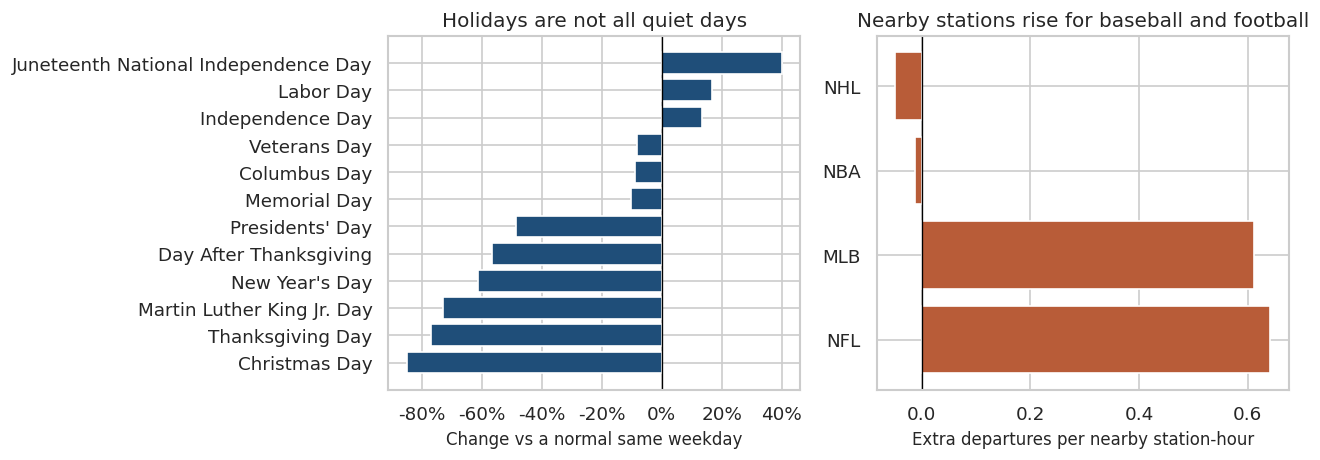

Saved 09_holidays_sports.png


In [13]:
holiday_days = (
    city.groupby("date", as_index=False)
    .agg(
        per_station=("per_station", "mean"),
        is_holiday=("is_holiday", "max"),
        holiday_name=("holiday_name", "first"),
        day_of_week=("day_of_week", "first"),
    )
)
baseline = (
    holiday_days.loc[~holiday_days["is_holiday"].fillna(False)]
    .groupby("day_of_week")["per_station"]
    .mean()
)
holiday_days["same_dow_baseline"] = holiday_days["day_of_week"].map(baseline)
named = holiday_days.loc[holiday_days["is_holiday"].fillna(False) & holiday_days["holiday_name"].notna()].copy()
named["vs_baseline"] = named["per_station"] / named["same_dow_baseline"] - 1
summary_holidays = (
    named.groupby("holiday_name")
    .agg(days=("date", "nunique"), vs_typical_same_weekday=("vs_baseline", "mean"))
    .query("days >= 2")
    .sort_values("vs_typical_same_weekday")
)
print("Holiday daily ridership relative to a normal day with the same weekday:")
print(summary_holidays.round(3).to_string())

sports = panel.loc[
    panel["near_sports"].fillna(False) & panel["sports_league"].notna(),
    ["station_id", "hour_of_day", "day_of_week", "departures", "sports_league"],
]
reference = (
    panel.loc[~panel["sports_any"].fillna(False)]
    .groupby(["station_id", "hour_of_day", "day_of_week"])["departures"]
    .mean()
    .rename("baseline")
)
sports = sports.join(reference, on=["station_id", "hour_of_day", "day_of_week"])
sports = sports.dropna(subset=["baseline"])
sports["lift"] = sports["departures"] - sports["baseline"]
league_rows = []
for league, part in sports.groupby("sports_league"):
    counts = part.groupby("station_id").size()
    keep = part.loc[part["station_id"].isin(counts[counts.ge(8)].index)]
    if keep.empty:
        continue
    station_lift = keep.groupby("station_id")["lift"].mean()
    league_rows.append(
        {
            "league": str(league).upper(),
            "stations": int(station_lift.size),
            "extra_departures": float(station_lift.mean()),
        }
    )
league_table = pd.DataFrame(league_rows).sort_values("extra_departures", ascending=False)
print("\nExtra departures at nearby stations during games, versus the same station and clock time:")
print(league_table.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_h = summary_holidays.sort_values("vs_typical_same_weekday")
axes[0].barh(plot_h.index.astype(str), plot_h["vs_typical_same_weekday"], color="#1f4e79")
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_xlabel("Change vs a normal same weekday")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:.0%}"))
axes[0].set_title("Holidays are not all quiet days")
if len(league_table):
    axes[1].barh(league_table["league"], league_table["extra_departures"], color="#b85c38")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_xlabel("Extra departures per nearby station-hour")
axes[1].set_title("Nearby stations rise for baseball and football")
save_figure(FIGURES / "09_holidays_sports.png", dpi=140)

## Empty docks and observed departures

This comparison uses only station-hours with a status snapshot. Within each station and hour
of day on weekdays, it contrasts hours when the minimum bike count was zero with hours when
at least one bike was seen. A pair is kept only when both conditions were observed at least
five times. Completed trips cannot show the rides that never started, so a negative gap is
not guaranteed. An empty dock can also be the trace of a busy hour: the bikes left, and
those departures are in the count.


Weekday station/hour pairs with both empty and stocked observations: 2,512
Mean paired difference, departures when empty minus departures when stocked: 0.104
Median paired difference: 0.120
Empty hours have more completed trips, not fewer. The snapshot is consistent with bikes leaving during a busy hour. Trips that could not start after the dock was empty are not in the file.


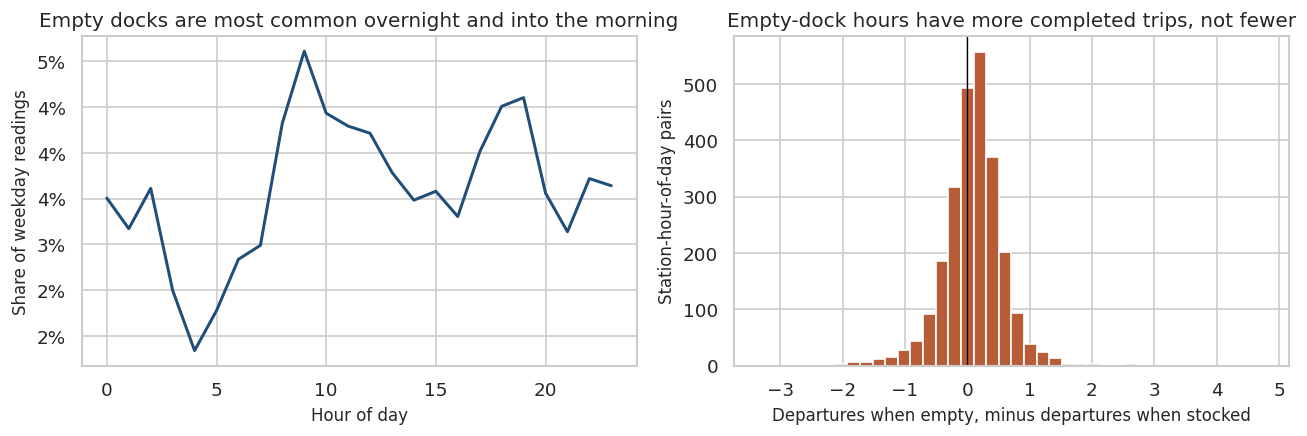

Saved 10_availability.png


In [14]:
observed = panel.loc[panel["bikes_available"].notna() & ~panel["is_weekend"]].copy()
observed["zero_bikes"] = observed["zero_bikes"].fillna(False).astype(bool)
stockout = observed.groupby("hour_of_day")["zero_bikes"].mean()

paired = (
    observed.groupby(["station_id", "hour_of_day", "zero_bikes"])
    .agg(departures=("departures", "mean"), n=("departures", "size"))
    .reset_index()
)
wide = paired.pivot_table(
    index=["station_id", "hour_of_day"],
    columns="zero_bikes",
    values=["departures", "n"],
)
wide = wide.dropna()
# After pivot, columns are a MultiIndex: (metric, zero_bikes flag).
enough = (wide[("n", False)] >= 5) & (wide[("n", True)] >= 5)
wide = wide.loc[enough]
wide["difference"] = wide[("departures", True)] - wide[("departures", False)]
print(f"Weekday station/hour pairs with both empty and stocked observations: {len(wide):,}")
print(
    "Mean paired difference, departures when empty minus departures when stocked: "
    f"{wide['difference'].mean():.3f}"
)
print(f"Median paired difference: {wide['difference'].median():.3f}")
print(
    "Empty hours have more completed trips, not fewer. "
    "The snapshot is consistent with bikes leaving during a busy hour. "
    "Trips that could not start after the dock was empty are not in the file."
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(stockout.index, stockout.values, color="#1f4e79", lw=1.8)
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Share of weekday readings")
axes[0].set_title("Empty docks are most common overnight and into the morning")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:.0%}"))
axes[1].hist(wide["difference"], bins=40, color="#b85c38", edgecolor="white")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_xlabel("Departures when empty, minus departures when stocked")
axes[1].set_ylabel("Station-hour-of-day pairs")
axes[1].set_title("Empty-dock hours have more completed trips, not fewer")
save_figure(FIGURES / "10_availability.png", dpi=140)

## Case study: SEPTA service cut and fare increase

The cut lasted three weeks in late summer, when Indego ridership is high for seasonal reasons.
The figure compares 2025 with the same calendar dates in 2024. The bars then compare each
2025 window with the same window a year earlier, using the three weeks before the cut as the
reference period. A fare increase that simply coincided with autumn would show up in 2024 as
well.


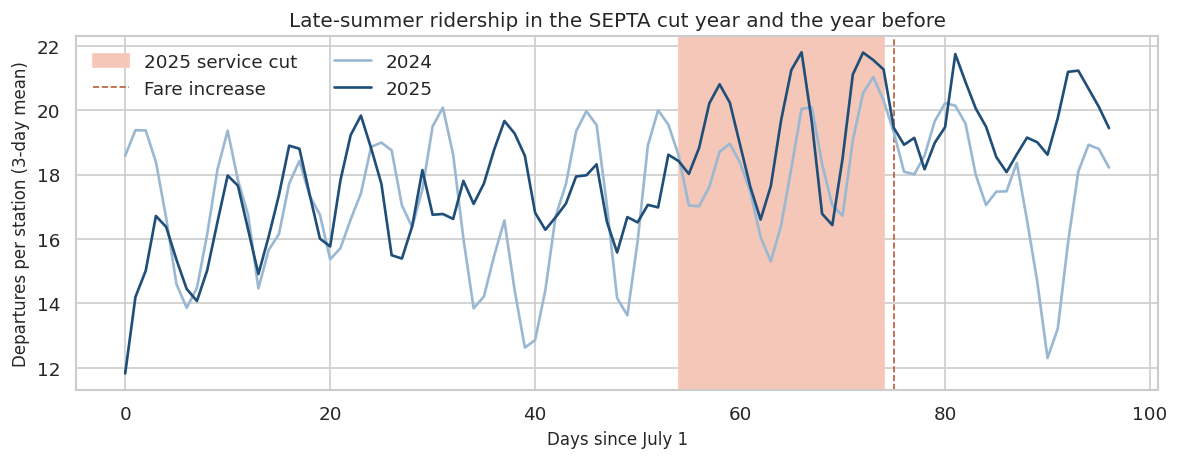

Saved 11_septa_daily.png
                window  per_station_2025  per_station_2024  vs_2024
    Three weeks before            17.558            16.417    0.070
           Service cut            19.441            18.278    0.064
First three fare weeks            19.578            17.580    0.114
2025 was already ahead of 2024 before the cut (7.0%). During the cut the gap was 6.4%.


In [15]:
def seasonal_slice(year: int, start_md: str, end_md: str) -> pd.DataFrame:
    start = pd.Timestamp(f"{year}-{start_md}")
    end = pd.Timestamp(f"{year}-{end_md}")
    part = daily.loc[daily["date"].between(start, end)].copy()
    part["year"] = year
    part["day_index"] = (part["date"] - start).dt.days
    part["window_start"] = start
    return part


overlay = pd.concat(
    [seasonal_slice(2024, "07-01", "10-05"), seasonal_slice(2025, "07-01", "10-05")],
    ignore_index=True,
)
cut_start = (pd.Timestamp("2025-08-24") - pd.Timestamp("2025-07-01")).days
cut_end = (pd.Timestamp("2025-09-13") - pd.Timestamp("2025-07-01")).days
fare_day = (pd.Timestamp("2025-09-14") - pd.Timestamp("2025-07-01")).days

fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(cut_start, cut_end, color="#f4c7b8", label="2025 service cut")
ax.axvline(fare_day, color="#b85c38", ls="--", lw=1, label="Fare increase")
for year, color in [(2024, "#9bb8d3"), (2025, "#1f4e79")]:
    part = overlay.loc[overlay["year"].eq(year)]
    ax.plot(part["day_index"], part["per_station"].rolling(3, min_periods=1).mean(), color=color, lw=1.6, label=str(year))
ax.set_xlabel("Days since July 1")
ax.set_ylabel("Departures per station (3-day mean)")
ax.set_title("Late-summer ridership in the SEPTA cut year and the year before")
ax.legend(frameon=False, ncol=2)
save_figure(FIGURES / "11_septa_daily.png", dpi=140)


def mean_per_station(start: str, end: str) -> float:
    part = daily.loc[daily["date"].between(start, end), "per_station"]
    return float(part.mean())


windows = [
    ("Three weeks before", "2025-08-03", "2025-08-23", "2024-08-03", "2024-08-23"),
    ("Service cut", "2025-08-24", "2025-09-13", "2024-08-24", "2024-09-13"),
    ("First three fare weeks", "2025-09-14", "2025-10-04", "2024-09-14", "2024-10-04"),
]
rows = []
for label, start, end, start_prev, end_prev in windows:
    current = mean_per_station(start, end)
    previous = mean_per_station(start_prev, end_prev)
    rows.append({"window": label, "per_station_2025": current, "per_station_2024": previous, "vs_2024": current / previous - 1})
septa_table = pd.DataFrame(rows)
print(septa_table.round(3).to_string(index=False))
pre_gap = septa_table.loc[septa_table["window"].eq("Three weeks before"), "vs_2024"].iloc[0]
cut_gap = septa_table.loc[septa_table["window"].eq("Service cut"), "vs_2024"].iloc[0]
print(
    "2025 was already ahead of 2024 before the cut "
    f"({pre_gap:.1%}). During the cut the gap was {cut_gap:.1%}."
)

## Case study: June 2026 World Cup matches

Five group-stage matches fall inside the published trips. Stations within 1.5 km of Lincoln
Financial Field are Broad & Pattison, the Phillies-adjacent docks, FDR Park, and a few
neighbors. The comparison is evening hours (16:00–23:00), which cover the published kickoffs,
against other June evenings. June 2025 is the seasonal control, matched on calendar day so
weekday mix is the same set of dates rather than a hand-picked week.


Stations within 1.5 km of Lincoln Financial Field: 7
         station_name  km_lff
Broad & Pattison, BSL    0.66
      10th & Phillies    0.76
        Crescent Park    0.82
             FDR Park    0.85
      12th & Normandy    0.92
        10th & Packer    1.07
    15th & Kitty Hawk    1.45


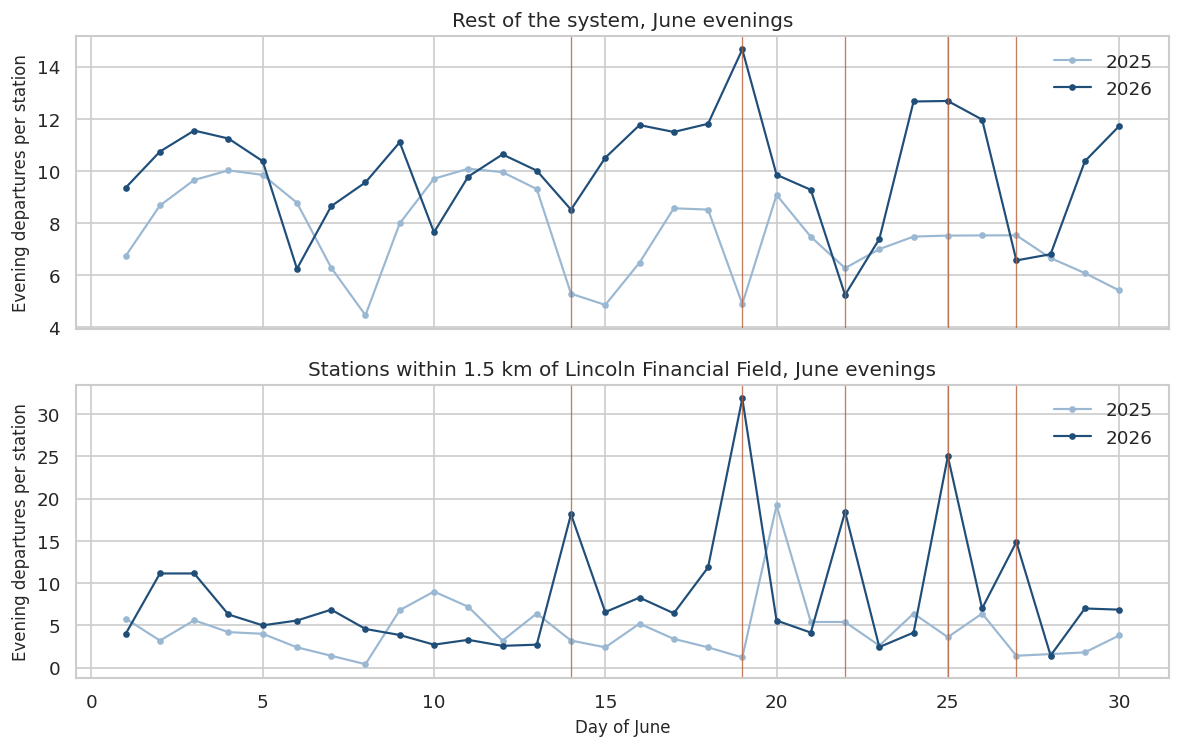

Saved 12_fifa_evenings.png
                    stations            evenings  per_station_2026  per_station_2025  vs_2025
Near Lincoln Financial Field      Match evenings            21.657             2.960    6.317
Near Lincoln Financial Field Other June evenings             5.657             4.808    0.177
              Rest of system      Match evenings             9.535             6.306    0.512
              Rest of system Other June evenings            10.102             7.869    0.284
July 4, 2026 station-hours in the panel: 0
Last trip hour: 2026-06-30 23:00:00
Figures written to figures/eda


In [16]:
located["km_lff"] = haversine_km(located["lat"], located["lon"], LFF[0], LFF[1])
stadium_ids = set(located.loc[located["km_lff"].le(1.5), "station_id"])
print(f"Stations within 1.5 km of Lincoln Financial Field: {len(stadium_ids)}")
print(
    located.loc[located["station_id"].isin(stadium_ids), ["station_name", "km_lff"]]
    .sort_values("km_lff")
    .round(2)
    .to_string(index=False)
)

evening = panel.loc[panel["hour_of_day"].between(16, 23) & panel["hour"].dt.month.eq(6)].copy()
evening["year"] = evening["hour"].dt.year
evening["stadium"] = evening["station_id"].isin(stadium_ids)
evening_daily = evening.groupby(["date", "year", "stadium"], as_index=False).agg(
    departures=("departures", "sum"),
    stations=("station_id", "nunique"),
)
evening_daily["per_station"] = evening_daily["departures"] / evening_daily["stations"]
evening_daily["day"] = evening_daily["date"].dt.day

fig, axes = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True)
for axis, stadium, title in [
    (axes[0], False, "Rest of the system, June evenings"),
    (axes[1], True, "Stations within 1.5 km of Lincoln Financial Field, June evenings"),
]:
    for year, color in [(2025, "#9bb8d3"), (2026, "#1f4e79")]:
        part = evening_daily.loc[evening_daily["stadium"].eq(stadium) & evening_daily["year"].eq(year)]
        axis.plot(part["day"], part["per_station"], marker="o", ms=3, lw=1.3, color=color, label=str(year))
    match_days = sorted(panel.loc[panel["is_fifa_match_day"].fillna(False), "date"].dt.day.unique())
    for day in match_days:
        axis.axvline(day, color="#b85c38", lw=0.8, alpha=0.8)
    axis.set_ylabel("Evening departures per station")
    axis.set_title(title)
    axis.legend(frameon=False)
axes[1].set_xlabel("Day of June")
save_figure(FIGURES / "12_fifa_evenings.png", dpi=140)


def evening_rate(year: int, stadium: bool, match_days: bool) -> float:
    part = evening.loc[evening["year"].eq(year) & evening["stadium"].eq(stadium)]
    if match_days:
        part = part.loc[part["is_fifa_match_day"].fillna(False)]
    else:
        part = part.loc[~part["is_fifa_match_day"].fillna(False)]
    # 2025 has no World Cup flag. Use the 2026 match calendar days as the control dates.
    if year == 2025:
        days = set(panel.loc[panel["is_fifa_match_day"].fillna(False), "date"].dt.day)
        if match_days:
            part = evening.loc[evening["year"].eq(2025) & evening["stadium"].eq(stadium) & evening["date"].dt.day.isin(days)]
        else:
            part = evening.loc[evening["year"].eq(2025) & evening["stadium"].eq(stadium) & ~evening["date"].dt.day.isin(days)]
    totals = part.groupby("date").agg(departures=("departures", "sum"), stations=("station_id", "nunique"))
    return float((totals["departures"] / totals["stations"]).mean())


fifa_rows = []
for stadium, label in [(True, "Near Lincoln Financial Field"), (False, "Rest of system")]:
    for kind, is_match in [("Match evenings", True), ("Other June evenings", False)]:
        y2026 = evening_rate(2026, stadium, is_match)
        y2025 = evening_rate(2025, stadium, is_match)
        fifa_rows.append(
            {
                "stations": label,
                "evenings": kind,
                "per_station_2026": y2026,
                "per_station_2025": y2025,
                "vs_2025": y2026 / y2025 - 1,
            }
        )
fifa_table = pd.DataFrame(fifa_rows)
print(fifa_table.round(3).to_string(index=False))
print(
    "July 4, 2026 station-hours in the panel:",
    int(panel["hour"].dt.normalize().eq(pd.Timestamp("2026-07-04")).sum()),
)
print("Last trip hour:", panel["hour"].max())

print("Figures written to", FIGURES.relative_to(ROOT))

## What this pass supports

Same-station lags around 0.46–0.49 mean a historical baseline is a real benchmark. Weather
moves weekday ridership in the expected direction: wet hours average about half the
departures of dry hours, and the gap remains after holding temperature fixed, until the
hottest bin. Ridership rises with temperature and then flattens.
Holidays are not one effect. Christmas and Thanksgiving are quiet; Juneteenth, Labor Day,
and Independence Day are busier than the same weekday. NFL and MLB hours add departures at
stations within 1.5 km of the venue; NBA and NHL hours do not.

An empty dock is not a clean marker of suppressed trips. Status covers about a quarter of
station-hours, and where a weekday dock is observed empty the station has more completed
departures than in stocked hours at the same clock time. The trips that never started are
still invisible.

The August 2025 SEPTA cut does not break the seasonal path. Per-station departures were
already about 7% above 2024 in the three weeks before the cut, and about 6% above 2024
during the cut. World Cup match evenings are different: stations within 1.5 km of Lincoln
Financial Field jump far above both their other June 2026 evenings and the same dates in
June 2025, and the rest of the system rises by less. July 4, 2026 is not in the trip files.


In [17]:
print("EDA summary")
print("Panel rows:", f"{len(panel):,}")
print("Study period:", panel["hour"].min(), "to", panel["hour"].max())
print("Stations:", f"{panel['station_id'].nunique():,}")
print("Figures saved to:", FIGURES.relative_to(ROOT))

EDA summary
Panel rows: 5,950,039
Study period: 2024-01-01 00:00:00 to 2026-06-30 23:00:00
Stations: 339
Figures saved to: figures/eda
